# Food-bank requirement prediction

This notebook trains a small PyTorch multilayer perceptron to predict `quantity_required` from food-bank, category, season, stock, and distribution information.

In [ ]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
FEATURE_COLUMNS = ["food_bank_id", "category", "season", "quantity_in_stock", "quantity_distributed"]
TARGET_COLUMN = "quantity_required"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [2]:
data_path = Path("../data/inventory_history.csv")
frame = pd.read_csv(data_path)

required_columns = set(FEATURE_COLUMNS + [TARGET_COLUMN])
missing_columns = required_columns.difference(frame.columns)
if missing_columns:
    raise ValueError(f"Missing required CSV columns: {sorted(missing_columns)}")

features = frame[FEATURE_COLUMNS].copy()
features["food_bank_id"] = features["food_bank_id"].astype(str)
categorical_columns = ["food_bank_id", "category", "season"]
category_values = {
    column: sorted(features[column].astype(str).unique().tolist())
    for column in categorical_columns
}
features = pd.get_dummies(
    features,
    columns=categorical_columns,
    dtype=np.float32,
)

targets = frame[TARGET_COLUMN].to_numpy(dtype=np.float32)
split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(features), generator=split_generator).numpy()
validation_size = max(1, int(len(features) * 0.2))
validation_indices = permutation[:validation_size]
training_indices = permutation[validation_size:]

training_means = {}
training_stds = {}
for numeric_column in ["quantity_in_stock", "quantity_distributed"]:
    training_means[numeric_column] = float(features[numeric_column].iloc[training_indices].mean())
    training_stds[numeric_column] = float(features[numeric_column].iloc[training_indices].std()) or 1.0
    features[numeric_column] = (features[numeric_column] - training_means[numeric_column]) / training_stds[numeric_column]

feature_tensor = torch.tensor(features.to_numpy(dtype=np.float32))
target_tensor = torch.tensor(targets)
training_dataset = TensorDataset(
    feature_tensor[training_indices], target_tensor[training_indices]
)
validation_dataset = TensorDataset(
    feature_tensor[validation_indices], target_tensor[validation_indices]
)
training_loader = DataLoader(training_dataset, batch_size=64, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=64)

print(f"Training records: {len(training_dataset)}")
print(f"Validation records: {len(validation_dataset)}")
print(f"Number of input features: {feature_tensor.shape[1]}")

Training records: 4000
Validation records: 1000
Number of input features: 19


In [3]:


class RequirementPredictor(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, inputs):
        return self.network(inputs).squeeze(1)


model = RequirementPredictor(feature_tensor.shape[1])
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 100

for epoch in range(1, epochs + 1):
    model.train()
    for batch_features, batch_targets in training_loader:
        optimizer.zero_grad()
        predictions = model(batch_features)
        loss = loss_function(predictions, batch_targets)
        loss.backward()
        optimizer.step()

    model.eval()
    validation_loss = 0.0
    validation_count = 0
    with torch.no_grad():
        for batch_features, batch_targets in validation_loader:
            batch_loss = loss_function(model(batch_features), batch_targets)
            validation_loss += batch_loss.item() * len(batch_targets)
            validation_count += len(batch_targets)
    validation_loss /= validation_count

    if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
        print(f"Epoch {epoch:>3}/{epochs} - validation MSE: {validation_loss:.4f}")

Epoch   1/100 - validation MSE: 3328.5216


Epoch  10/100 - validation MSE: 39.4551


Epoch  20/100 - validation MSE: 41.8551


Epoch  30/100 - validation MSE: 39.2491


Epoch  40/100 - validation MSE: 39.5723


...

Epoch  60/100 - validation MSE: 40.2672


Epoch  70/100 - validation MSE: 39.5894


Epoch  80/100 - validation MSE: 39.5494


Epoch  90/100 - validation MSE: 40.2925


Epoch 100/100 - validation MSE: 39.3549


In [4]:
model.eval()
absolute_error = 0.0
sample_count = 0
with torch.no_grad():
    for batch_features, batch_targets in validation_loader:
        absolute_error += torch.abs(model(batch_features) - batch_targets).sum().item()
        sample_count += len(batch_targets)

validation_mae = absolute_error / sample_count
print(f"Validation MSE: {validation_loss:.4f}")
print(f"Validation MAE: {validation_mae:.4f}")

checkpoint = {
    "model_state_dict": model.state_dict(),
    "model_input_size": feature_tensor.shape[1],
    "feature_names": features.columns.tolist(),
    "category_values": category_values,
    "numeric_feature_means": training_means,
    "numeric_feature_stds": training_stds,
    "validation_mse": validation_loss,
    "validation_mae": validation_mae,
}
torch.save(checkpoint, "../quantity_required_model.pt")
print("Saved model checkpoint to ../quantity_required_model.pt")

Validation MSE: 39.3549
Validation MAE: 3.6859
Saved model checkpoint to ../quantity_required_model.pt


## Model evaluation

The model predicts a continuous quantity, so classification accuracy and a confusion matrix are not native regression metrics. The evaluation below reports MSE, RMSE, MAE, R², and tolerance accuracy. It also bins requirements into five demand bands for an interpretable confusion matrix; those bands are only for visualization.

,Metric,Value
0,MSE,39.354858
1,RMSE,6.273345
2,MAE,3.685894
3,R²,0.983394
4,Accuracy (+/-10),83.100000


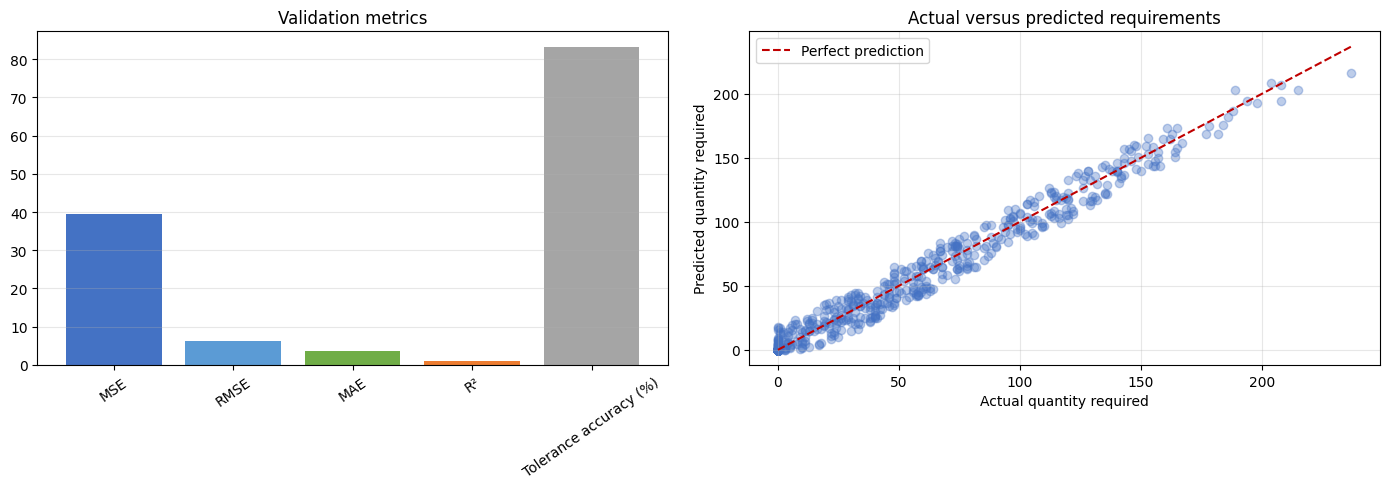

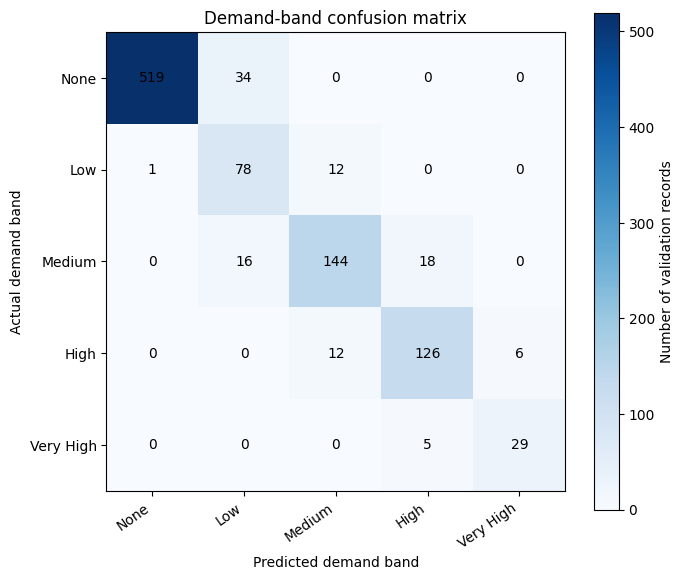

In [5]:
import matplotlib.pyplot as plt

model.eval()
actual_values = []
predicted_values = []
with torch.inference_mode():
    for batch_features, batch_targets in validation_loader:
        actual_values.extend(batch_targets.numpy())
        predicted_values.extend(model(batch_features).numpy())

actual_values = np.asarray(actual_values, dtype=np.float32)
predicted_values = np.asarray(predicted_values, dtype=np.float32)
errors = predicted_values - actual_values
mse = float(np.mean(errors ** 2))
rmse = float(np.sqrt(mse))
mae = float(np.mean(np.abs(errors)))
total_variation = float(np.sum((actual_values - actual_values.mean()) ** 2))
r_squared = 1.0 - float(np.sum(errors ** 2)) / total_variation if total_variation else 0.0
accuracy_tolerance = 10.0
tolerance_accuracy = float(np.mean(np.abs(errors) <= accuracy_tolerance) * 100)

metrics = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R²", f"Accuracy (+/-{accuracy_tolerance:g})"],
    "Value": [mse, rmse, mae, r_squared, tolerance_accuracy],
})
display(metrics)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
metric_names = ["MSE", "RMSE", "MAE", "R²", "Tolerance accuracy (%)"]
metric_values = [mse, rmse, mae, r_squared, tolerance_accuracy]
axes[0].bar(metric_names, metric_values, color=["#4472c4", "#5b9bd5", "#70ad47", "#ed7d31", "#a5a5a5"])
axes[0].set_title("Validation metrics")
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(axis="y", alpha=0.3)
axes[1].scatter(actual_values, predicted_values, alpha=0.35, color="#4472c4")
line_min = min(actual_values.min(), predicted_values.min())
line_max = max(actual_values.max(), predicted_values.max())
axes[1].plot([line_min, line_max], [line_min, line_max], "--", color="#c00000", label="Perfect prediction")
axes[1].set_title("Actual versus predicted requirements")
axes[1].set_xlabel("Actual quantity required")
axes[1].set_ylabel("Predicted quantity required")
axes[1].legend()
axes[1].grid(alpha=0.3)
figure.tight_layout()
plt.show()

band_edges = np.array([-np.inf, 0, 25, 75, 150, np.inf])
band_labels = ["None", "Low", "Medium", "High", "Very High"]
actual_bands = np.digitize(actual_values, band_edges[1:-1], right=True)
predicted_bands = np.digitize(np.maximum(predicted_values, 0), band_edges[1:-1], right=True)
confusion = np.zeros((len(band_labels), len(band_labels)), dtype=int)
np.add.at(confusion, (actual_bands, predicted_bands), 1)

figure, axis = plt.subplots(figsize=(7, 6))
image = axis.imshow(confusion, cmap="Blues")
figure.colorbar(image, ax=axis, label="Number of validation records")
axis.set_xticks(range(len(band_labels)), band_labels, rotation=35, ha="right")
axis.set_yticks(range(len(band_labels)), band_labels)
axis.set_xlabel("Predicted demand band")
axis.set_ylabel("Actual demand band")
axis.set_title("Demand-band confusion matrix")
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        axis.text(column, row, confusion[row, column], ha="center", va="center")
figure.tight_layout()
plt.show()

checkpoint.update({
    "validation_mse": mse,
    "validation_rmse": rmse,
    "validation_mae": mae,
    "validation_r_squared": r_squared,
    "validation_tolerance_accuracy": tolerance_accuracy,
    "accuracy_tolerance": accuracy_tolerance,
    "demand_band_edges": band_edges.tolist(),
    "demand_band_labels": band_labels,
})
torch.save(checkpoint, "../quantity_required_model.pt")